# P3.10 — Who benefits from a cut in IMI or IMT?

**Question:** RQ7.4 (who benefits most from IMI/IMT cuts, and how much passes through to lower housing costs versus higher
prices?). `p3_02`–`p3_03` covered the pass-through of IMI into prices (inconclusive); this notebook covers the first half, the incidence.

**What the data allow.** Municipal data only, so the groups are tenures and places, not households by income: a municipality's median
income stands in for who lives there. (1) The **IMI** bill of a typical dwelling (`p3_08`: price times area times the urban rate,
scaled to national IMI) is applied to every dwelling of the municipality by use (census 2021: lived in by the owner, let, other
tenure, second home, vacant). The cut is the one of the simulator's IMI package, 0.05 pp, limited by the legal 0.30% floor
(`p3_05`). (2) The **IMT** cut of one point of the price falls on the value of dwellings sold (`p3_05`), by municipality.
Accounting, not behaviour; who gets the money if nobody changes what they do.

**Reading rule, fixed before looking:** a cut is "regressive" across municipalities if the third with the lowest median income gets a
smaller share of it than its share of dwellings, and "reaching where housing is dearest" if the third with the highest price-to-income
gets at least its share of dwellings. Municipalities with similar incomes can differ widely in tenure, so these are statements about
places, not people.

In [1]:
import pandas as pd

from pthousing.analysis import incidence as inc
from pthousing.analysis import revenue, supply
from pthousing.config import PROCESSED
from pthousing.data import interim, typology
from pthousing.viz import charts, style

style.apply_style()
YEAR, CUT_PP = 2024, 0.05
panel = pd.read_parquet(PROCESSED / "panel_municipality_year.parquet")
d = panel[panel["year"] == YEAR].set_index("muni_code")
stock = supply.read_stock()
uses = inc.dwellings_by_use(stock, interim.read("ine_census"))
dwellings = stock[stock["census_year"] == 2021].set_index("muni_code")["dwellings_n"]
imi_national = float(
    interim.read("eurostat_property_tax").set_index("year").loc[YEAR, "imi_revenue_eur_m"]
)
per_dwelling = revenue.imi_per_dwelling(panel, YEAR)
scale = revenue.calibration(per_dwelling, dwellings, imi_national)
unit = per_dwelling * scale
rate = d["imi_urban_pct"]
cut_pp = inc.capped(rate, CUT_PP)
ty = typology.read().set_index("muni_code")
print(
    f"IMI {imi_national:,.0f} EUR m; typical bill {unit.mean():.0f} EUR; {int((cut_pp > 0).sum())} of {rate.notna().sum()} councils can cut, {int((cut_pp >= CUT_PP - 1e-9).sum())} in full"
)

IMI 1,677 EUR m; typical bill 183 EUR; 102 of 300 councils can cut, 70 in full


## Step 1 — Who holds the dwellings, who pays IMI and who gets the cut
By use of the dwelling (census 2021). The bill per dwelling is the municipality's typical one, so the shares of the bill differ from the
shares of dwellings only through the municipalities where each use is common. The cut is 0.05 pp where the council is above
the floor (102 of 300 councils; 70 can cut in full).

In [2]:
bill = uses.mul(unit, axis=0).dropna()
saving = inc.imi_cut_by_use(uses, unit, rate, cut_pp)
by_use = pd.DataFrame(
    {
        "dwellings_n": uses.sum(),
        "dwellings_share_pct": inc.shares(uses),
        "bill_share_pct": inc.shares(bill),
        "cut_share_pct": inc.shares(saving),
        "cut_eur_m": saving.sum() / 1e6,
    }
)
by_use.index = [inc.USE_LABELS[u] for u in by_use.index]
by_use.loc["total"] = [
    by_use["dwellings_n"].sum(),
    100,
    100,
    100,
    by_use["cut_eur_m"].sum(),
]
style.save_table(by_use.round(2).rename_axis("use").reset_index(), "p3", "imi_incidence_by_use")
by_use.round(1)

,dwellings_n,dwellings_share_pct,bill_share_pct,cut_share_pct,cut_eur_m
lived in by the owner,2900093.0,48.6,48.4,50.5,48.2
let to a tenant,922810.0,15.5,18.2,17.9,17.0
"lived in, other tenure",319678.0,5.4,5.6,5.6,5.4
second home,1104881.0,18.5,16.2,15.2,14.5
vacant,723215.0,12.1,11.7,10.8,10.3
total,5970677.0,100.0,100.0,100.0,95.4


In [3]:
cut_shares = inc.shares(saving)
print(
    f"the cut goes {cut_shares['owner_occupied']:.0f}% to owners living in the home, {cut_shares['rented']:.0f}% to landlords, "
    f"{cut_shares[['secondary', 'vacant']].sum():.0f}% to owners of second or empty homes; tenants get nothing unless it is passed on "
    f"({uses['rented'].sum():,.0f} dwellings let, {uses['owner_occupied'].sum():,.0f} lived in by the owner)"
)

the cut goes 51% to owners living in the home, 18% to landlords, 26% to owners of second or empty homes; tenants get nothing unless it is passed on (922,810 dwellings let, 2,900,093 lived in by the owner)


## Step 2 — Which places
Municipalities in thirds of the 2024 median income and of the price-to-income (lowest first), and by density. Shares of the IMI cut,
of the IMI bill, of dwellings, and of the value of dwellings sold (the base of an IMT cut); bill and IMT cut as a share of
the municipality's median income.

In [4]:
frame = pd.DataFrame(
    {
        "dwellings_n": dwellings,
        "bill_eur": uses.mul(unit, axis=0).sum(axis=1, min_count=5),
        "imi_cut_eur": saving.sum(axis=1),
        "sales_value_eur": inc.sales_value(panel, YEAR),
        "sales_n": d["sales_12m_n"],
        "income_median_eur": d["income_median_eur"],
        "pti_years": d["pti_years"],
        "unit_eur": unit,
        "owner_occupied_n": uses["owner_occupied"],
    }
)
frame["imt_cut_eur"] = 0.01 * frame["sales_value_eur"]
frame["income_third"] = inc.terciles(
    frame["income_median_eur"], ("lowest income", "middle", "highest income")
)
frame["pti_third"] = inc.terciles(
    frame["pti_years"], ("most affordable", "middle", "least affordable")
)
frame = frame.join(ty[["density_class"]])
COLS = {
    "dwellings_n": "dwellings",
    "bill_eur": "imi_bill",
    "imi_cut_eur": "imi_cut",
    "sales_value_eur": "sales_value",
    "imt_cut_eur": "imt_cut",
}
tables = {}
for name, group in (
    ("income_third", "income_third"),
    ("pti_third", "pti_third"),
    ("density_class", "density_class"),
):
    g = inc.by_group(frame.dropna(subset=[group]), frame.dropna(subset=[group])[group], COLS)
    sub = frame.dropna(subset=[group]).groupby(group, observed=True)
    g["municipalities_n"] = sub.size()
    g["income_median_eur"] = sub["income_median_eur"].median()
    g["imi_bill_per_dwelling_eur"] = g["imi_bill"] / g["dwellings"]
    g["imi_bill_pct_of_income"] = 100 * g["imi_bill_per_dwelling_eur"] / g["income_median_eur"]
    g["imi_cut_per_owner_eur"] = g["imi_cut"] / sub["owner_occupied_n"].sum()
    g["imt_cut_per_sale_eur"] = g["imt_cut"] / sub["sales_n"].sum()
    g["imt_cut_per_sale_pct_of_income"] = 100 * g["imt_cut_per_sale_eur"] / g["income_median_eur"]
    tables[name] = g.drop(columns=["dwellings", "imi_bill", "imi_cut", "sales_value", "imt_cut"])
    style.save_table(tables[name].round(2).reset_index(), "p3", f"tax_cut_incidence_by_{name}")
pd.set_option("display.width", 220)
for name, g in tables.items():
    print(name)
    print(g.round(2).to_string())
    print()

income_third
                dwellings_share_pct  imi_bill_share_pct  imi_cut_share_pct  sales_value_share_pct  imt_cut_share_pct  municipalities_n  income_median_eur  imi_bill_per_dwelling_eur  imi_bill_pct_of_income  imi_cut_per_owner_eur  imt_cut_per_sale_eur  imt_cut_per_sale_pct_of_income
income_third                                                                                                                                                                                                                                                                             
lowest income                 17.62                8.78               2.79                   6.11               6.11               108            10972.5                     136.54                    1.24                   5.69                928.77                            8.46
middle                        22.17               19.52              18.46                  17.56              17.56                91       

## Step 3 — A cut that is capitalised goes to the seller, not the buyer
What the IMT cut of one point (294 EUR m) leaves with buyers, sellers and nobody, at three capitalisation shares (`p3_02`: IMI is
inconclusive between 0 and full capitalisation; the simulator runs both ends). Buyers and sellers are the two sides of the same
sale, so there is no difference by place, only by who they are, which the data do not give. An IMI cut that is capitalised is a one-off
gain to the owners at the time of the cut, and none to later buyers or to tenants.

In [5]:
imt_total = frame["imt_cut_eur"].sum()
sales_n = frame["sales_n"].sum()
pass_through = pd.DataFrame(
    {
        "capitalised_share": [0.0, 0.5, 1.0],
        "buyers_keep_eur_m": [imt_total / 1e6 * (1 - c) for c in (0.0, 0.5, 1.0)],
        "sellers_get_eur_m": [imt_total / 1e6 * c for c in (0.0, 0.5, 1.0)],
    }
)
pass_through["buyer_keeps_per_sale_eur"] = pass_through["buyers_keep_eur_m"] * 1e6 / sales_n
pass_through["seller_gets_per_sale_eur"] = pass_through["sellers_get_eur_m"] * 1e6 / sales_n
style.save_table(pass_through.round(1), "p3", "imt_cut_pass_through")
pass_through.round(1)

,capitalised_share,buyers_keep_eur_m,sellers_get_eur_m,buyer_keeps_per_sale_eur,seller_gets_per_sale_eur
0,0.0,294.4,0.0,1942.0,0.0
1,0.5,147.2,147.2,971.0,971.0
2,1.0,0.0,294.4,0.0,1942.0


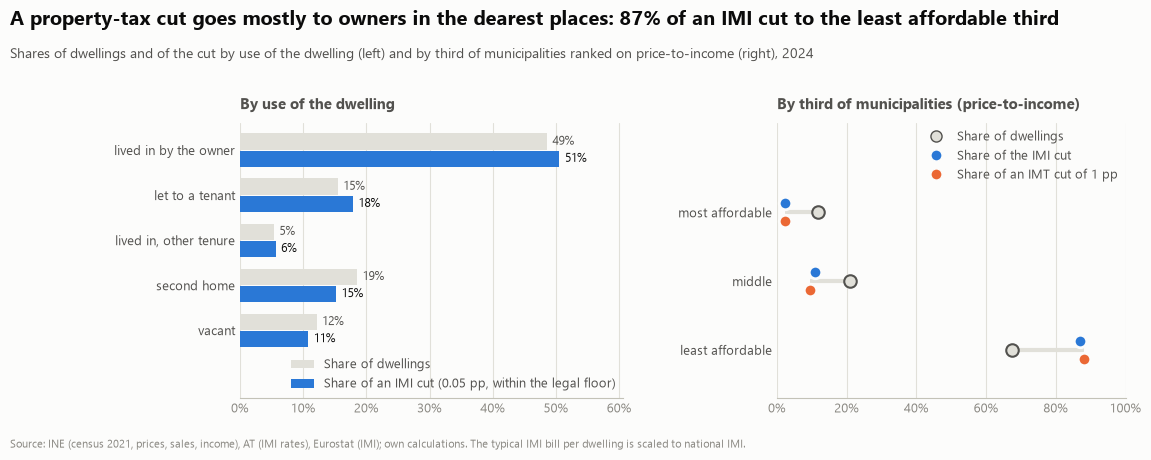

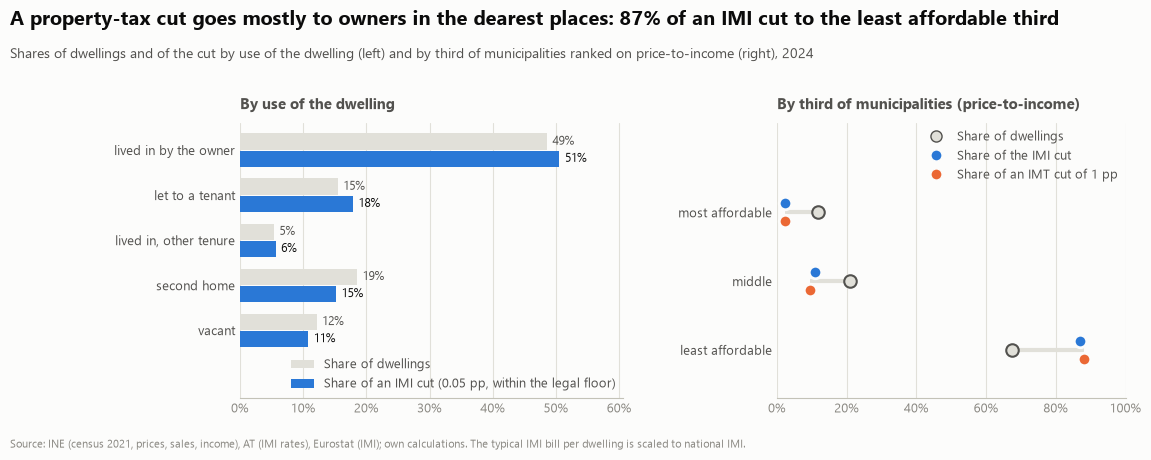

In [6]:
fig = charts.tax_cut_incidence(by_use.drop(index="total"), tables["pti_third"])
style.save_fig(fig, "p3", "tax_cut_incidence")
fig

## Findings

1. **A quarter of an IMI cut goes to homes nobody lives in, and tenants get none (RQ7.4).** Of the 95 EUR m a year that a 0.05 pp cut
   delivers inside the legal floor (102 of 300 councils can cut, 70 in full; the unconstrained package would be 276 EUR m): 51% to owners
   living in the home (49% of dwellings), 18% to landlords (15% of dwellings, 17 EUR m), 6% to other tenure, 15% to second homes and 11% to
   vacant ones (19% and 12% of dwellings). The 0.92 million rented dwellings house about a fifth of households, who gain only if the
   landlord passes it on, which nothing in the data measures.
2. **The cut is concentrated in the dearest places.** In the third of municipalities with the highest price-to-income (67% of dwellings)
   an IMI cut delivers 87% of its value and an IMT cut of 1 pp 88%; the most affordable third (12% of dwellings) gets 2% of either. By
   income, the highest third (60% of dwellings) gets 79% of the IMI cut and 76% of the IMT cut, the lowest third (18% of dwellings) 3% and 6%.
   By the reading rule fixed in advance the IMI cut is regressive across places and reaches where housing is dearest.
3. **The cut is small where the need is lower and larger in euros where houses cost more.** The yearly IMI of a typical dwelling is 137 EUR in
   the lowest-income third (1.2% of its median income), 241 in the middle and 326 in the highest (2.5%); an IMT cut of 1 pp is 929 EUR a
   sale in the lowest (8.5% of the median income there), 1,638 and 2,234 (17.0%). By density: urban municipalities (40% of dwellings) get 55% of
   an IMI cut and 60% of an IMT cut, rural ones (27%) 10% of each.
4. **How much stays with the buyer depends on capitalisation.** Of an IMT cut of 294 EUR m (1,942 EUR a sale), buyers keep all if none is
   capitalised, half (971 EUR a sale) at the midpoint of the bound and nothing if it is all capitalised, when sellers get 1,942 EUR a sale. The
   capitalisation of IMI is inconclusive between 0 and 1 (`p3_02`, `p3_03`), so the incidence between buyers, sellers and tenants is a bound,
   not a number.

**Limits.** Municipalities, not households or incomes: a municipal median income is an average of a place, and the groups are thirds
of municipalities, not of people. The IMI bill of a dwelling is the municipality's typical one, the same for every use and every owner,
scaled to national IMI (which covers commercial and rustic property, so the bill is an upper bound for dwellings); old, low-assessed homes
are not told apart. Eight municipalities with parish-specific rates are left out. The IMT base is transactions times the median price of a
100 m2 dwelling, not registered values; buyers and sellers are not observed by age or income; no behavioural response; the pass-through to
tenants is not observed.